# Practical No. 04: Image Generation using DCGAN

**Goal:** train a Deep Convolutional GAN on Fashion-MNIST, generate synthetic grayscale clothing images, and analyze the generated samples and adversarial losses.

This notebook uses PyTorch. Training from scratch may take several minutes; a CUDA GPU is recommended. The defaults are set for a practical demonstration and can be increased for better image quality.

## 1. Setup

Install the required packages in your environment before running the notebook. The dataset will be downloaded automatically by `torchvision`.

In [1]:
%pip install torch torchvision matplotlib

Import libraries for data handling, visualization, neural network layers, optimization, and Fashion-MNIST.

In [2]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils

Set a random seed for repeatability and select CUDA when available. Fashion-MNIST contains 28×28 grayscale images in ten clothing categories.

Set reproducible random seeds and choose a GPU when one is available.

In [3]:
seed = 42
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


## 2. Dataset preparation

The generator ends in `Tanh`, so pixel values are normalized to `[-1, 1]`. `drop_last=True` keeps training batches the same size.

Download Fashion-MNIST, normalize images to the generator output range, and create shuffled training batches.

In [4]:
image_size, channels = 28, 1
batch_size = 128
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
dataset = datasets.FashionMNIST('data', train=True, download=True, transform=transform)
loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True,
                    num_workers=0, pin_memory=(device.type == 'cuda'))
print('Training images:', len(dataset))

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 273kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 4.98MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.3MB/s]


Training images: 60000


Preview real training images. Their grayscale range is normalized for stable GAN training.

Display a small batch of real dataset images as a visual reference.Display a small batch of real dataset images as a visual reference.

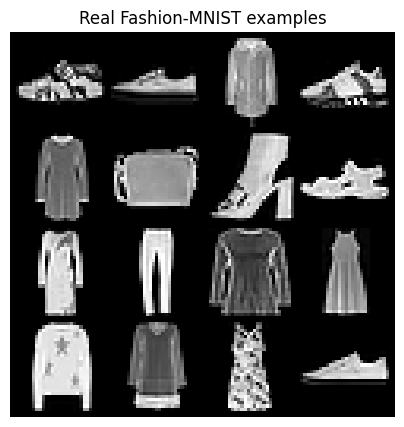

In [5]:
real, _ = next(iter(loader))
grid = utils.make_grid(real[:16], nrow=4, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(5, 5)); plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap='gray')
plt.axis('off'); plt.title('Real Fashion-MNIST examples'); plt.show()

## 3. DCGAN architecture

The generator upsamples a latent noise vector through transposed convolutions. The discriminator downsamples an image through convolutions and outputs one real/fake logit. Batch normalization stabilizes intermediate activations; the discriminator uses strided convolutions instead of pooling.

Define the Generator that transforms a 100-dimensional noise vector into a 28×28 grayscale image.

In [6]:
latent_dim = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, 7, 1, 0, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, channels, 4, 2, 1, bias=False), nn.Tanh()
        )
    def forward(self, z): return self.net(z)

Define the Discriminator that scores each 28×28 image as real or generated.

In [7]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(channels, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1)
        )
    def forward(self, image): return self.net(image).view(-1)

Initialize convolution weights with the common DCGAN scheme. BCE-with-logits combines sigmoid and binary cross entropy in a numerically stable loss. Adam uses the DCGAN learning rate and momentum settings.

Initialize model weights, configure the adversarial loss, and create separate Adam optimizers for both networks.

In [8]:
def init_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.BatchNorm2d)):
        nn.init.normal_(module.weight.data, 0.0, 0.02)
        if getattr(module, 'bias', None) is not None: nn.init.zeros_(module.bias.data)

G, D = Generator().to(device), Discriminator().to(device)
G.apply(init_weights); D.apply(init_weights)
criterion = nn.BCEWithLogitsLoss()
opt_G = optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_D = optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))
print('Generator parameters:', sum(p.numel() for p in G.parameters()))
print('Discriminator parameters:', sum(p.numel() for p in D.parameters()))

Generator parameters: 759680
Discriminator parameters: 138625


## 4. Adversarial training

For each batch, the discriminator learns to score real images as 1 and generated images as 0. Then the generator updates to make generated images score as real. The generator sees fresh noise; a fixed noise batch is retained for comparing samples across epochs. Loss values can oscillate because the two networks continually adapt.

Set the training duration, fixed noise for comparable sample previews, history lists, and output folder.

In [11]:
epochs = 10
fixed_noise = torch.randn(64, latent_dim, 1, 1, device=device)
g_losses, d_losses, snapshots = [], [], []
os.makedirs('outputs', exist_ok=True)

Train the Discriminator on real and detached generated images, then train the Generator to fool it; record average losses and fixed-noise samples each epoch.

In [12]:
for epoch in range(epochs):
    sum_g = sum_d = 0.0
    for real, _ in loader:
        real = real.to(device); n = real.size(0)
        ones = torch.ones(n, device=device); zeros = torch.zeros(n, device=device)

        # Update discriminator on real and detached fake images
        opt_D.zero_grad(set_to_none=True)
        loss_real = criterion(D(real), ones)
        fake = G(torch.randn(n, latent_dim, 1, 1, device=device))
        loss_fake = criterion(D(fake.detach()), zeros)
        loss_D = loss_real + loss_fake
        loss_D.backward(); opt_D.step()

        # Update generator to fool the discriminator
        opt_G.zero_grad(set_to_none=True)
        loss_G = criterion(D(fake), ones)
        loss_G.backward(); opt_G.step()
        sum_d += loss_D.item(); sum_g += loss_G.item()

    avg_d, avg_g = sum_d / len(loader), sum_g / len(loader)
    d_losses.append(avg_d); g_losses.append(avg_g)
    with torch.no_grad(): snapshots.append(G(fixed_noise).cpu())
    print(f'Epoch {epoch+1:02d}/{epochs} | D loss: {avg_d:.3f} | G loss: {avg_g:.3f}')

Epoch 01/10 | D loss: 0.463 | G loss: 1.768
Epoch 02/10 | D loss: 0.493 | G loss: 1.962
Epoch 03/10 | D loss: 0.638 | G loss: 1.725
Epoch 04/10 | D loss: 0.737 | G loss: 1.506
Epoch 05/10 | D loss: 0.825 | G loss: 1.382
Epoch 06/10 | D loss: 0.900 | G loss: 1.308
Epoch 07/10 | D loss: 0.938 | G loss: 1.254
Epoch 08/10 | D loss: 0.973 | G loss: 1.212
Epoch 09/10 | D loss: 1.017 | G loss: 1.180
Epoch 10/10 | D loss: 1.021 | G loss: 1.173


## 5. Loss curves and generated images

Inspect both losses together with sample grids. GAN losses are not accuracy scores and need not decrease smoothly. A healthy run often shows fluctuations while both models keep learning; loss curves alone cannot establish image quality.

Plot Generator and Discriminator losses across epochs to inspect adversarial training behavior.

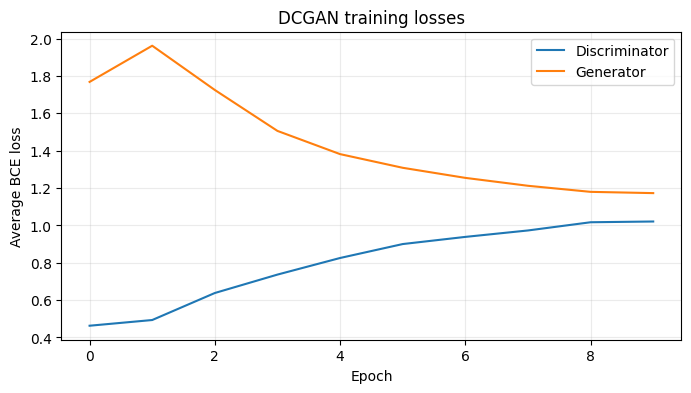

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(d_losses, label='Discriminator'); plt.plot(g_losses, label='Generator')
plt.xlabel('Epoch'); plt.ylabel('Average BCE loss'); plt.title('DCGAN training losses')
plt.legend(); plt.grid(alpha=.25); plt.show()

Display the final batch of generated images as a grid for visual quality inspection.

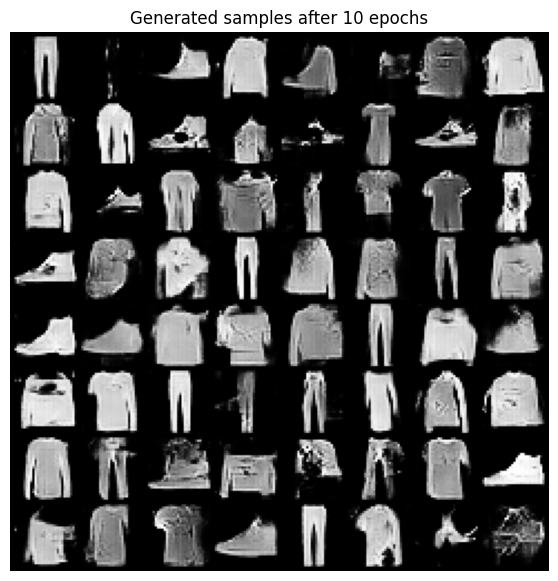

In [14]:
def show_samples(images, title):
    grid = utils.make_grid(images[:64], nrow=8, normalize=True, value_range=(-1, 1))
    plt.figure(figsize=(7, 7)); plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap='gray')
    plt.axis('off'); plt.title(title); plt.show()

show_samples(snapshots[-1], f'Generated samples after {epochs} epochs')

Show fixed-noise generated samples from early, middle, and final training checkpoints to compare progress and variety.

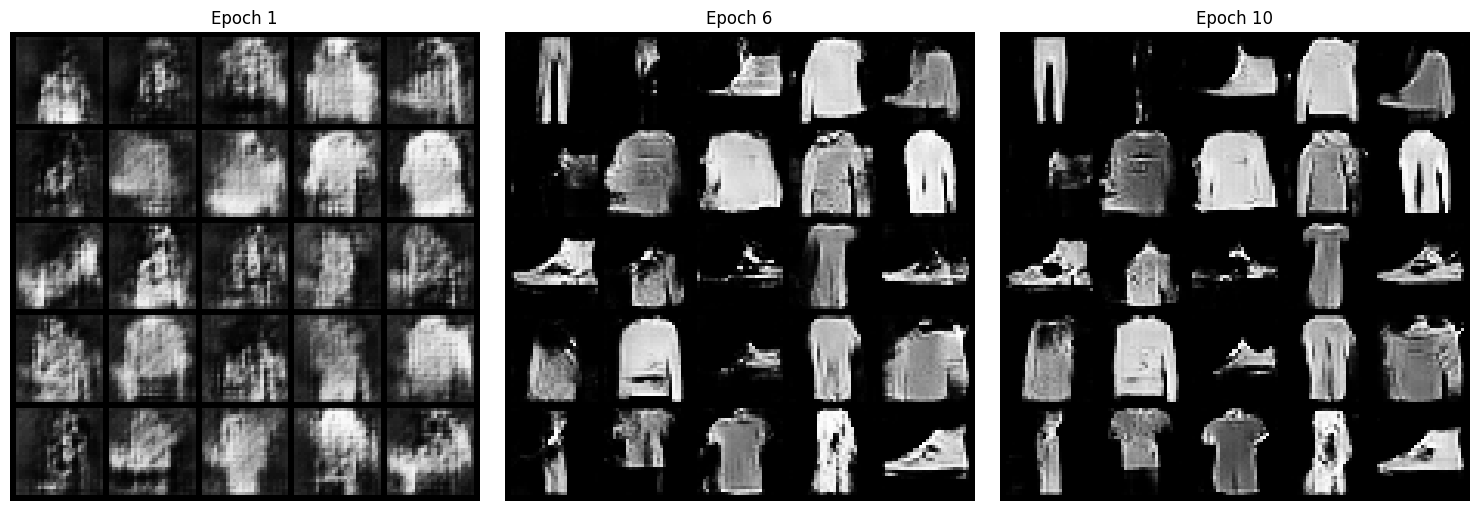

In [15]:
checkpoints = sorted(set([0, len(snapshots)//2, len(snapshots)-1]))
fig, axes = plt.subplots(1, len(checkpoints), figsize=(5 * len(checkpoints), 5))
if len(checkpoints) == 1: axes = [axes]
for ax, idx in zip(axes, checkpoints):
    grid = utils.make_grid(snapshots[idx][:25], nrow=5, normalize=True, value_range=(-1, 1))
    ax.imshow(grid.permute(1, 2, 0).squeeze(), cmap='gray'); ax.axis('off')
    ax.set_title(f'Epoch {idx+1}')
plt.tight_layout(); plt.show()

## 6. Simple diversity check and save results

The average per-pixel standard deviation across generated samples is a rough diversity indicator: values near zero suggest similar outputs. It is not a perceptual metric and cannot replace visual inspection or metrics such as FID. Save the final sample grid and model weights for the demonstration.

Calculate a rough pixel-wise diversity indicator across generated samples; use it only alongside visual inspection.

In [16]:
final_images = snapshots[-1]
pixel_diversity = final_images.flatten(1).std(dim=0).mean().item()
print(f'Average pixel-wise standard deviation: {pixel_diversity:.4f}')
print('Use the sample grid to check whether outputs cover different clothing shapes and textures.')

Average pixel-wise standard deviation: 0.5324
Use the sample grid to check whether outputs cover different clothing shapes and textures.


Save the final generated sample grid and both network weights with loss histories for later demonstration.

In [17]:
grid = utils.make_grid(final_images, nrow=8, normalize=True, value_range=(-1, 1))
utils.save_image(grid, 'outputs/dcgan_fashion_samples.png')
torch.save({'generator': G.state_dict(), 'discriminator': D.state_dict(),
            'g_losses': g_losses, 'd_losses': d_losses},
           'outputs/dcgan_fashion_mnist.pt')
print('Saved sample grid and model checkpoint in outputs/.')

Saved sample grid and model checkpoint in outputs/.
